# Week 6: Feature Engineering and School-District Layer

**Question:** do engineered structural/temporal features and a school-district location layer improve the v2 baseline (LR, DT, RF)?

**Protocol (same as Weeks 4-5):** chronological split, seed 42. Train = 2025-05..2026-04, test = 2026-05 (scored **once per final model**), validation = train 2025-04..2026-03 vs 2026-04 for every choice. All learned steps (clipping, imputation, scaling, rare-district grouping, target encoding, price bounds) are fit on training rows only, inside sklearn Pipelines.

**Feature sets:** F0 = v2 baseline (old) | F1 = F0 + engineered features | F2 = F0 + school district | F3 = F1 + school district.

Validation results (all four sets) were produced by `scratch/week6_validation.py` and are loaded from `outputs/week6_validation.csv`. Final fits and test scoring run live in this notebook.

In [1]:
import time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mt, seaborn as sns
from IPython.display import Markdown, display

import geo, features as ft, model_pipeline as mp, plot_style as ps

warnings.filterwarnings('ignore', category=FutureWarning)
ps.apply_style()
SEED = 42
np.random.seed(SEED)
pd.set_option('display.width', 200)

v2 = pd.read_csv('outputs/02_preprocessed_v2.csv', dtype={'PostalCode': 'object'})
print(f'v2 modeling table: {len(v2):,} rows x {v2.shape[1]} cols')

v2 modeling table: 153,714 rows x 17 cols


## 1. School-district spatial join
Boundaries: CA School District Areas 2024-25 (data.ca.gov), downloaded 2026-10-29 to `data/external/`, zip SHA-256 `9a01b8d01bdb6b150798bebaeab29987cd30a7ec0aab1af72a5109fedd3cc86f`.
Points are reprojected to the polygon CRS (EPSG:3310) before the join. Districts overlap by type, so the primary `SchoolDistrict` is Unified, else Elementary, else High; ties keep the smallest-area polygon; the row count must be unchanged. Enrollment/ethnicity/poverty columns in the boundary file are deliberately dropped (protected-class proxies). The join is a static geographic lookup that never uses price, so doing it before the split is not leakage.

In [2]:
districts = geo.load_districts()
print(f'{len(districts)} district polygons ({districts.attrs["n_invalid_repaired"]} invalid geometries repaired); types:',
      districts['DistrictTy'].value_counts().to_dict())
joined = geo.assign_school_districts(v2, districts)
assert len(joined) == len(v2), 'row count changed by spatial join'
print(f'rows before join {len(v2):,} | after join {len(joined):,} (asserted equal)')
report = geo.match_report(joined)
display(report.style.format({'rows': '{:,.0f}', 'pct': '{:.3f}%'}))
print('primary district type:', joined['SchoolDistrictType'].value_counts().to_dict())
print(f'distinct primary districts: {joined["SchoolDistrict"].nunique()} | '
      f'districts with <20 homes: {int((joined["SchoolDistrict"].value_counts() < 20).sum())}')
display(joined['SchoolDistrictName'].value_counts().head(10).rename('homes').to_frame())

937 district polygons (6 invalid geometries repaired); types: {'Elementary': 516, 'Unified': 345, 'High': 76}


rows before join 153,714 | after join 153,714 (asserted equal)


,rows,pct
total,"153,714",100.000%
matched,"153,638",99.951%
unmatched,76,0.049%
null lat/lon,14,0.009%
outside CA bbox / zero,47,0.031%
"inside CA, no polygon",15,0.010%


primary district type: {'Unified': 116510, 'Elementary': 37128, 'Unknown': 76}
distinct primary districts: 651 | districts with <20 homes: 267


,homes
SchoolDistrictName,
Los Angeles Unified,15398
San Diego Unified,4187
Desert Sands Unified,2867
Capistrano Unified,2820
Palm Springs Unified,2504
Oakland Unified,2004
Corona-Norco Unified,1895
Long Beach Unified,1886
Hemet Unified,1836


## 2. Engineered features and leakage audit
All engineered columns are deterministic row-wise functions of intrinsic fields known before sale (invalid input -> NaN; clipping/imputation/missing-indicators are learned in-pipeline on train only).

| Feature | Definition | Source columns | Missing rule | Rationale |
|---|---|---|---|---|
| `BedBathRatio` | Bedrooms / max(Bathrooms, 1) | Bedrooms, Bathrooms | NaN if Bathrooms NaN | layout/privacy proxy |
| `PropertyAge` | CloseYear - YearBuilt, clipped to [0, 150] | YearBuilt, CloseDate | YearBuilt <1800 or > CloseYear+1 -> NaN | condition/vintage |
| `LivingArea_per_Bedroom` | LivingArea / max(Bedrooms, 1) | LivingArea, Bedrooms | none | room size, luxury proxy |
| `Lot_to_Living_ratio` | LotSize / max(LivingArea, 200) | LotSize, LivingArea | NaN if LotSize NaN | land share of value |
| `SaleMonth_sin/cos` | sin/cos(2 pi month / 12) | CloseDate | none | seasonality |
| `SchoolDistrict` | polygon containing the property (CDSCode) | Latitude, Longitude | 'Unknown' | local school/neighborhood effect |

In [3]:
data = ft.add_engineered_features(joined)
train, bounds = mp.filter_train_prices(data.loc[data['split'].eq('train')])
test = data.loc[data['split'].eq('test')]
val_train, _ = mp.filter_train_prices(data.loc[data['val_split'].eq('train')])
val_rows = data.loc[data['val_split'].eq('val')]
print(f'train {len(train):,} (price bounds ${bounds[0]:,.0f}-${bounds[1]:,.0f} learned on train) | test {len(test):,} | '
      f'val-train {len(val_train):,} | val {len(val_rows):,}')
data.to_csv('outputs/03_features_v3.csv', index=False)

y_log = np.log(train[mp.TARGET])
audit = pd.DataFrame({'uses ClosePrice?': 'no', 'corr with log price (train)': train[ft.ENGINEERED].corrwith(y_log),
                      'NaN rate (train)': train[ft.ENGINEERED].isna().mean(),
                      'min': train[ft.ENGINEERED].min(), 'median': train[ft.ENGINEERED].median(),
                      'max': train[ft.ENGINEERED].max()})
display(audit.style.format({'corr with log price (train)': '{:+.3f}', 'NaN rate (train)': '{:.2%}',
                            'min': '{:,.2f}', 'median': '{:,.2f}', 'max': '{:,.2f}'}))
assert audit['corr with log price (train)'].abs().max() < 0.95, 'leakage suspect'
print(f'max |corr| = {audit["corr with log price (train)"].abs().max():.3f} (< 0.95 leakage threshold). Forbidden fields '
      '(ListPrice, DOM, price reductions, post-close fields) are not in the table.')

train 127,939 (price bounds $235,000-$8,900,000 learned on train) | test 12,015 | val-train 127,734 | val 12,021


,uses ClosePrice?,corr with log price (train),NaN rate (train),min,median,max
BedBathRatio,no,-0.280,0.01%,0.00,1.50,7.50
PropertyAge,no,+0.059,0.05%,0.00,49.00,150.00
LivingArea_per_Bedroom,no,+0.437,0.00%,91.75,542.00,"5,744.00"
Lot_to_Living_ratio,no,-0.012,1.73%,0.00,4.22,"1,570,930.26"
SaleMonth_sin,no,+0.010,0.00%,-1.00,-0.00,1.00
SaleMonth_cos,no,-0.028,0.00%,-1.00,-0.00,1.00


max |corr| = 0.437 (< 0.95 leakage threshold). Forbidden fields (ListPrice, DOM, price reductions, post-close fields) are not in the table.


## 3. Validation ablation and feature-set selection
Every choice below uses validation (April 2026) only. DT depth 18 / leaf 5 and RF leaf 3 are the Week 5 settings, held fixed so that feature sets are compared like-for-like (note: in the sensitivity check below, depth 24 beat depth 18 on F0 validation, and the final DT test fit still used depth 18, listed as a limitation). Validation R2 is ignored (three April sales of $645M+ hold ~98% of the variance); MdAPE and MAE decide.

**Selection rule (fixed before any test scoring):** a model moves off F0 only if the best alternative set improves validation MdAPE by at least **0.10 percentage points** AND also improves validation MAE. Otherwise F0 is kept. The 0.10 pp threshold is a judgment call (the plan did not specify one); it is meant to avoid chasing differences that small.

In [4]:
vr = pd.read_csv('outputs/week6_validation.csv')
vr = vr.loc[~vr['district_encoding'].str.startswith('onehot_mf')]
best = vr.sort_values('MdAPE').groupby(['model', 'feature_set']).head(1).sort_values(['model', 'feature_set']).reset_index(drop=True)
base = best.loc[best['feature_set'].eq('F0')].set_index('model')
best['dMdAPE_pp'] = [(r.MdAPE - base.loc[r.model, 'MdAPE']) * 100 for r in best.itertuples()]
best['dMAE_pct'] = [(r.MAE / base.loc[r.model, 'MAE'] - 1) * 100 for r in best.itertuples()]
show = best[['model', 'feature_set', 'district_encoding', 'MAE', 'MdAPE', 'dMdAPE_pp', 'dMAE_pct', 'R2']].copy()
display(show.style.format({'MAE': '${:,.0f}', 'MdAPE': '{:.2%}', 'dMdAPE_pp': '{:+.2f} pp', 'dMAE_pct': '{:+.2f}%', 'R2': '{:.4f}'})
        .hide(axis='index'))
print('Encoding comparison for district sets (validation, all rows):')
display(vr.loc[vr['feature_set'].isin(['F2', 'F3'])].pivot_table(index=['model', 'feature_set'], columns='district_encoding',
        values='MdAPE').style.format('{:.2%}'))

MIN_GAIN = 0.0010
chosen = {}
for m in ['LR', 'DT', 'RF']:
    cand = best.loc[best['model'].eq(m) & ~best['feature_set'].eq('F0')].sort_values('MdAPE').iloc[0]
    gain = base.loc[m, 'MdAPE'] - cand['MdAPE']
    ok = gain >= MIN_GAIN and cand['MAE'] < base.loc[m, 'MAE']
    chosen[m] = (cand['feature_set'], cand['district_encoding']) if ok else ('F0', 'none')
    print(f'{m}: best alternative {cand["feature_set"]}/{cand["district_encoding"]} gain {gain*100:+.2f} pp MdAPE, '
          f'MAE {"better" if cand["MAE"] < base.loc[m, "MAE"] else "worse"} -> chosen {chosen[m][0]}')

model,feature_set,district_encoding,MAE,MdAPE,dMdAPE_pp,dMAE_pct,R2
DT,F0,none,"$443,501",10.39%,+0.00 pp,+0.00%,0.0079
DT,F1,none,"$453,177",10.65%,+0.26 pp,+2.18%,0.0076
DT,F2,target,"$444,088",10.28%,-0.11 pp,+0.13%,0.0083
DT,F3,target,"$449,810",10.56%,+0.17 pp,+1.42%,0.0085
LR,F0,none,"$422,895",9.77%,+0.00 pp,+0.00%,0.0095
LR,F1,none,"$420,829",9.65%,-0.11 pp,-0.49%,0.0096
LR,F2,onehot,"$418,444",9.69%,-0.08 pp,-1.05%,0.0098
LR,F3,onehot,"$416,710",9.62%,-0.15 pp,-1.46%,0.0099
RF,F0,none,"$407,159",8.16%,+0.00 pp,+0.00%,0.0081
RF,F1,none,"$408,770",8.18%,+0.02 pp,+0.40%,0.0081


Encoding comparison for district sets (validation, all rows):


LR: best alternative F3/onehot gain +0.15 pp MdAPE, MAE better -> chosen F3
DT: best alternative F2/target gain +0.11 pp MdAPE, MAE worse -> chosen F0
RF: best alternative F2/onehot gain +0.05 pp MdAPE, MAE better -> chosen F0


### Hyperparameter and grouping sensitivity (validation only)
To test whether fixed hyperparameters biased the feature-set comparison:
1. **Decision Tree grid extension:** depth {14, 18, 24} x min_samples_leaf {5, 20} evaluated on F0 and on the best new set (F2 target encoding).
2. **Linear Regression district min_frequency sweep:** min_frequency {5, 20, 50} on F3 one-hot.

In [5]:
dt_sweep = []
for fs, enc in [('F0', 'none'), ('F2', 'target')]:
    cols = ft.input_columns(fs, 'tree')
    for depth in [14, 18, 24]:
        for leaf in [5, 20]:
            m = ft.make_model('DT', fs, district_encoding='onehot' if enc == 'none' else enc,
                              max_depth=depth, min_samples_leaf=leaf)
            m.fit(val_train[cols], val_train[mp.TARGET])
            metrics = ft.full_metrics(val_rows[mp.TARGET], m.predict(val_rows[cols]))
            dt_sweep.append({'feature_set': fs, 'encoding': enc, 'max_depth': depth, 'min_samples_leaf': leaf,
                             'val_MAE': metrics['MAE'], 'val_MdAPE': metrics['MdAPE']})

df_dt_sweep = pd.DataFrame(dt_sweep)
display(df_dt_sweep.style.format({'val_MAE': '${:,.0f}', 'val_MdAPE': '{:.2%}'}).hide(axis='index'))

lr_mf_sweep = []
cols_lr = ft.input_columns('F3', 'lr')
for mf in [5, 20, 50]:
    m = ft.make_model('LR', 'F3', 'onehot', district_min_frequency=mf)
    m.fit(val_train[cols_lr], val_train[mp.TARGET])
    metrics = ft.full_metrics(val_rows[mp.TARGET], m.predict(val_rows[cols_lr]))
    lr_mf_sweep.append({'feature_set': 'F3', 'district_min_frequency': mf,
                        'val_MAE': metrics['MAE'], 'val_MdAPE': metrics['MdAPE'], 'val_R2': metrics['R2']})

df_lr_mf = pd.DataFrame(lr_mf_sweep)
display(df_lr_mf.style.format({'val_MAE': '${:,.0f}', 'val_MdAPE': '{:.2%}', 'val_R2': '{:.4f}'}).hide(axis='index'))
f0_d18 = df_dt_sweep.loc[df_dt_sweep['feature_set'].eq('F0') & df_dt_sweep['max_depth'].eq(18) & df_dt_sweep['min_samples_leaf'].eq(5), 'val_MdAPE'].iloc[0]
f0_best = df_dt_sweep.loc[df_dt_sweep['feature_set'].eq('F0'), 'val_MdAPE'].min()
f2_best = df_dt_sweep.loc[df_dt_sweep['feature_set'].eq('F2'), 'val_MdAPE'].min()
dt_delta_pp = (f0_best - f2_best) * 100
lr_mf_min, lr_mf_max = df_lr_mf['val_MdAPE'].min(), df_lr_mf['val_MdAPE'].max()
lr_mae_span = df_lr_mf['val_MAE'].max() - df_lr_mf['val_MAE'].min()
print(f'Finding: DT depth extension to 24 improves F0 validation MdAPE from {f0_d18:.2%} (depth 18) to {f0_best:.2%} (depth 24); '
      f'compared to tuned F2 target ({f2_best:.2%}), the delta is only {dt_delta_pp:.3f} pp (< {MIN_GAIN*100:.2f} pp), '
      f'and the final DT test fit still uses depth 18 (listed as a limitation). '
      f'LR F3 is essentially tied across min_frequency thresholds ({lr_mf_min:.2%} to {lr_mf_max:.2%} MdAPE, '
      f'MAE span ${lr_mae_span:,.0f}). Neither sweep alters the chosen configurations '
      f'(LR {chosen["LR"][0]}, DT {chosen["DT"][0]}, RF {chosen["RF"][0]}).')

feature_set,encoding,max_depth,min_samples_leaf,val_MAE,val_MdAPE
F0,none,14,5,"$455,044",11.21%
F0,none,14,20,"$459,965",11.26%
F0,none,18,5,"$443,501",10.39%
F0,none,18,20,"$449,810",10.43%
F0,none,24,5,"$443,174",10.27%
F0,none,24,20,"$448,391",10.29%
F2,target,14,5,"$448,501",10.79%
F2,target,14,20,"$446,254",10.84%
F2,target,18,5,"$444,088",10.28%
F2,target,18,20,"$440,560",10.24%


feature_set,district_min_frequency,val_MAE,val_MdAPE,val_R2
F3,5,"$416,675",9.58%,0.0099
F3,20,"$416,707",9.62%,0.0099
F3,50,"$416,885",9.62%,0.0099


Finding: DT depth extension to 24 improves F0 validation MdAPE from 10.39% (depth 18) to 10.27% (depth 24); compared to tuned F2 target (10.24%), the delta is only 0.035 pp (< 0.10 pp), and the final DT test fit still uses depth 18 (listed as a limitation). LR F3 is essentially tied across min_frequency thresholds (9.58% to 9.62% MdAPE, MAE span $209). Neither sweep alters the chosen configurations (LR F3, DT F0, RF F0).


### Selection threshold sensitivity table
The selection rule requires >= 0.10 pp validation MdAPE gain AND lower MAE to adopt a new feature set. **Note:** the 0.10 pp threshold was set as a judgment call after viewing the validation table (to avoid adopting complex sets for negligible sub-0.10 pp differences). The table below demonstrates what each model would choose across different threshold levels (0.050, 0.100, and 0.200 pp), with computed gains shown to 3 decimals:

In [6]:
sens_rows = []
for thresh in [0.0005, 0.0010, 0.0020]:
    row = {'Threshold (pp MdAPE)': f'{thresh*100:.3f} pp'}
    for m in ['LR', 'DT', 'RF']:
        cand = best.loc[best['model'].eq(m) & ~best['feature_set'].eq('F0')].sort_values('MdAPE').iloc[0]
        gain = base.loc[m, 'MdAPE'] - cand['MdAPE']
        mae_better = cand['MAE'] < base.loc[m, 'MAE']
        choice = cand['feature_set'] if (gain >= thresh and mae_better) else 'F0'
        row[m] = f'{choice} (best alt {cand["feature_set"]}: gain {gain*100:+.3f} pp, MAE {"better" if mae_better else "worse"})'
    sens_rows.append(row)

df_sens = pd.DataFrame(sens_rows)
display(df_sens.style.hide(axis='index'))

Threshold (pp MdAPE),LR,DT,RF
0.050 pp,"F3 (best alt F3: gain +0.146 pp, MAE better)","F0 (best alt F2: gain +0.111 pp, MAE worse)","F0 (best alt F2: gain +0.046 pp, MAE better)"
0.100 pp,"F3 (best alt F3: gain +0.146 pp, MAE better)","F0 (best alt F2: gain +0.111 pp, MAE worse)","F0 (best alt F2: gain +0.046 pp, MAE better)"
0.200 pp,"F0 (best alt F3: gain +0.146 pp, MAE better)","F0 (best alt F2: gain +0.111 pp, MAE worse)","F0 (best alt F2: gain +0.046 pp, MAE better)"


## 4. Final fit and single test scoring
For each model, the old set (F0) and its chosen set are refit on the full train window and the test month is scored **once**. Regression guard: the F0 rows must reproduce the Week 4/5 numbers.

In [7]:
PARAMS = {'LR': {}, 'DT': {'max_depth': 18, 'min_samples_leaf': 5}, 'RF': {'min_samples_leaf': 3}}
to_run = []
for m in ['LR', 'DT', 'RF']:
    to_run.append((m, 'F0', 'none'))
    if chosen[m][0] != 'F0':
        to_run.append((m, *chosen[m]))

def build(m, fs, enc):
    return ft.make_model(m, fs, district_encoding='onehot' if enc == 'none' else enc, **PARAMS[m])

rows, preds, models = [], {}, {}
for m, fs, enc in to_run:
    cols = ft.input_columns(fs, 'lr' if m == 'LR' else 'tree')
    model = build(m, fs, enc)
    t = time.perf_counter(); model.fit(train[cols], train[mp.TARGET]); fit_s = time.perf_counter() - t
    p_train = model.predict(train[cols])
    p_test = model.predict(test[cols])                     # the single test scoring of this configuration
    tm, trm = ft.full_metrics(test[mp.TARGET], p_test), ft.full_metrics(train[mp.TARGET], p_train)
    v = best.loc[best['model'].eq(m) & best['feature_set'].eq(fs)].iloc[0]
    n_feat = len(model.regressor_.named_steps['prep'].get_feature_names_out())
    rows.append({'model': m, 'feature_set': fs, 'description': ft.FEATURE_SET_DESCRIPTION[fs], 'district_encoding': enc,
                 'n_features': n_feat, **{f'test_{k}': val for k, val in tm.items()}, 'train_R2': trm['R2'], 'fit_s': fit_s,
                 'val_MAE': v['MAE'], 'val_MdAPE': v['MdAPE']})
    preds[(m, fs)] = p_test
    models[(m, fs)] = model
    print(f'{m} {fs}: test R2 {tm["R2"]:.4f} MAE ${tm["MAE"]:,.0f} MdAPE {tm["MdAPE"]:.2%} ({fit_s:.0f}s)')

comp = pd.DataFrame(rows)
b0 = comp.loc[comp['feature_set'].eq('F0')].set_index('model')
comp['dMAE'] = [r.test_MAE - b0.loc[r.model, 'test_MAE'] for r in comp.itertuples()]
comp['dMdAPE_pp'] = [(r.test_MdAPE - b0.loc[r.model, 'test_MdAPE']) * 100 for r in comp.itertuples()]
comp['dR2'] = [r.test_R2 - b0.loc[r.model, 'test_R2'] for r in comp.itertuples()]
comp.to_csv('outputs/week6_comparison.csv', index=False)

LR F0: test R2 0.4860 MAE $235,941 MdAPE 9.80% (0s)


LR F3: test R2 0.5024 MAE $228,644 MdAPE 9.59% (2s)


DT F0: test R2 0.4303 MAE $256,543 MdAPE 10.32% (2s)


RF F0: test R2 0.4445 MAE $220,621 MdAPE 8.19% (85s)


In [8]:
# Regression guard: F0 must reproduce the Week 4/5 baselines (PROJECT_CONTEXT section 6)
expected = {'LR': (0.4860, 235941, 0.0980), 'DT': (0.4303, 256543, 0.1032), 'RF': (0.4445, 220621, 0.0819)}
for m, (r2, mae, mdape) in expected.items():
    r = b0.loc[m]
    ok = abs(r.test_R2 - r2) < 5e-4 and abs(r.test_MAE - mae) < 2 and abs(r.test_MdAPE - mdape) < 5e-4
    print(f'{m} F0 reproduces Week 5: {ok} (R2 {r.test_R2:.4f} vs {r2}, MAE ${r.test_MAE:,.0f} vs ${mae:,}, MdAPE {r.test_MdAPE:.2%} vs {mdape:.2%})')
    assert ok, f'{m} baseline drifted'

fmt = {'test_R2': '{:.4f}', 'test_MAE': '${:,.0f}', 'test_RMSE': '${:,.0f}', 'test_MAPE': '{:.2%}', 'test_MdAPE': '{:.2%}',
       'train_R2': '{:.3f}', 'fit_s': '{:.1f}', 'val_MAE': '${:,.0f}', 'val_MdAPE': '{:.2%}', 'dMAE': '{:+,.0f}',
       'dMdAPE_pp': '{:+.2f}', 'dR2': '{:+.4f}'}
display(comp.drop(columns=['description']).style.format(fmt).hide(axis='index'))

LR F0 reproduces Week 5: True (R2 0.4860 vs 0.486, MAE $235,941 vs $235,941, MdAPE 9.80% vs 9.80%)
DT F0 reproduces Week 5: True (R2 0.4303 vs 0.4303, MAE $256,543 vs $256,543, MdAPE 10.32% vs 10.32%)
RF F0 reproduces Week 5: True (R2 0.4445 vs 0.4445, MAE $220,621 vs $220,621, MdAPE 8.19% vs 8.19%)


model,feature_set,district_encoding,n_features,test_R2,test_MAE,test_RMSE,test_MAPE,test_MdAPE,train_R2,fit_s,val_MAE,val_MdAPE,dMAE,dMdAPE_pp,dR2
LR,F0,none,1106,0.4860,"$235,941","$1,201,880",18.37%,9.80%,0.842,0.4,"$422,895",9.77%,+0,+0.00,+0.0000
LR,F3,onehot,1483,0.5024,"$228,644","$1,182,626",18.18%,9.59%,0.854,2.2,"$416,710",9.62%,"-7,297",-0.21,+0.0163
DT,F0,none,1110,0.4303,"$256,543","$1,265,392",18.63%,10.32%,0.921,2.2,"$443,501",10.39%,+0,+0.00,+0.0000
RF,F0,none,1110,0.4445,"$220,621","$1,249,535",15.91%,8.19%,0.951,84.7,"$407,159",8.16%,+0,+0.00,+0.0000


### Old vs new feature sets: test scores for reporting only, not used for any selection
This is the Week 6 deliverable table covering all four feature sets ($F_0, F_1, F_2, F_3$) across all three model architectures on the test set (May 2026).
**Important:** these test scores are presented strictly for reporting and deliverable completeness; model selections were frozen previously based solely on the April 2026 validation split and are not altered by this table. Also saved as `outputs/week6_comparison_full.csv`.

In [9]:
full_comp = pd.read_csv('outputs/week6_comparison_full.csv')
fmt_full = {'R2': '{:.4f}', 'MAE': '${:,.0f}', 'RMSE': '${:,.0f}', 'MAPE': '{:.2%}', 'MdAPE': '{:.2%}',
            'train_R2': '{:.3f}', 'fit_s': '{:.1f}'}
display(full_comp.style.format(fmt_full).hide(axis='index'))

model,feature_set,district_encoding,n_features,R2,MAE,RMSE,MAPE,MdAPE,train_R2,fit_s
LR,F0,none,1106,0.4860,"$235,941","$1,201,880",18.37%,9.80%,0.842,0.4
LR,F1,none,1115,0.4891,"$233,620","$1,198,315",18.44%,9.74%,0.847,0.7
LR,F2,onehot,1474,0.4989,"$231,027","$1,186,674",18.11%,9.59%,0.850,1.5
LR,F3,onehot,1483,0.5024,"$228,645","$1,182,624",18.18%,9.58%,0.854,2.2
DT,F0,none,1110,0.4303,"$256,543","$1,265,392",18.63%,10.32%,0.921,2.2
DT,F1,none,1119,0.4255,"$265,479","$1,270,634",19.82%,10.63%,0.922,3.4
DT,F2,target,1111,0.4501,"$250,068","$1,243,118",20.29%,10.15%,0.917,2.5
DT,F3,target,1120,0.4515,"$258,035","$1,241,533",19.25%,10.41%,0.920,3.8
RF,F0,none,1110,0.4445,"$220,621","$1,249,535",15.91%,8.19%,0.951,88.4
RF,F1,none,1119,0.4423,"$223,377","$1,252,003",16.22%,8.17%,0.953,147.9


### Is any change bigger than noise?
Paired bootstrap over the 12,015 test homes (seed 42, 2,000 resamples) of the change in MdAPE and MAE between each chosen set and F0. This is a descriptive check, not used for any selection.

In [10]:
rng = np.random.default_rng(SEED)
y_te = test[mp.TARGET].to_numpy()
boot = []
for m, fs, enc in to_run:
    if fs == 'F0':
        continue
    ape_new = np.abs(preds[(m, fs)] - y_te) / y_te
    ape_old = np.abs(preds[(m, 'F0')] - y_te) / y_te
    ae_new, ae_old = np.abs(preds[(m, fs)] - y_te), np.abs(preds[(m, 'F0')] - y_te)
    idx = rng.integers(0, len(y_te), size=(2000, len(y_te)))
    d_md = np.median(ape_new[idx], axis=1) - np.median(ape_old[idx], axis=1)
    d_mae = ae_new[idx].mean(axis=1) - ae_old[idx].mean(axis=1)
    boot.append({'model': m, 'vs F0': fs, 'dMdAPE pp': 100 * (np.median(ape_new) - np.median(ape_old)),
                 'dMdAPE 95% CI (pp)': f'[{100*np.percentile(d_md, 2.5):+.2f}, {100*np.percentile(d_md, 97.5):+.2f}]',
                 'dMAE': ae_new.mean() - ae_old.mean(), 'dMAE 95% CI': f'[{np.percentile(d_mae, 2.5):+,.0f}, {np.percentile(d_mae, 97.5):+,.0f}]'})
boot_df = pd.DataFrame(boot)
display(boot_df.style.format({'dMdAPE pp': '{:+.2f}', 'dMAE': '{:+,.0f}'}).hide(axis='index'))

model,vs F0,dMdAPE pp,dMdAPE 95% CI (pp),dMAE,dMAE 95% CI
LR,F3,-0.21,"[-0.33, -0.08]","-7,297","[-9,324, -5,443]"


## 5. Error breakdowns
MdAPE by price quintile (quintile edges from the **training** prices) and by large school districts, old vs chosen feature set.

In [11]:
edges = np.quantile(train[mp.TARGET], [.2, .4, .6, .8])
q = np.digitize(y_te, edges)
qlabel = ['Q1 (lowest)', 'Q2', 'Q3', 'Q4', 'Q5 (highest)']
qtab = {}
for (m, fs), p in preds.items():
    ape = np.abs(p - y_te) / y_te
    qtab[f'{m} {fs}'] = [np.median(ape[q == i]) for i in range(5)]
qtab = pd.DataFrame(qtab, index=qlabel)
qtab.insert(0, 'n test homes', [int((q == i).sum()) for i in range(5)])
display(qtab.style.format({c: '{:.2%}' for c in qtab.columns[1:]}))
qtab.to_csv('outputs/week6_mdape_by_quintile.csv')

tmp = test.assign(**{f'{m} {fs}': np.abs(p - y_te) / y_te for (m, fs), p in preds.items()})
big = tmp.groupby('SchoolDistrictName').filter(lambda d: len(d) >= 100)
dtab = big.groupby('SchoolDistrictName')[[f'{m} {fs}' for (m, fs) in preds]].median()
dtab.insert(0, 'n test homes', big.groupby('SchoolDistrictName').size())
display(dtab.sort_values('n test homes', ascending=False).style.format({c: '{:.2%}' for c in dtab.columns[1:]}))

,n test homes,LR F0,LR F3,DT F0,RF F0
Q1 (lowest),2333,9.08%,8.93%,9.62%,7.21%
Q2,2205,8.10%,7.96%,8.19%,6.10%
Q3,2225,7.87%,7.88%,8.53%,6.60%
Q4,2548,9.86%,9.72%,11.07%,8.83%
Q5 (highest),2704,14.81%,14.09%,15.69%,12.73%


,n test homes,LR F0,LR F3,DT F0,RF F0
SchoolDistrictName,,,,,
Los Angeles Unified,1175,11.66%,11.62%,13.52%,11.23%
San Diego Unified,310,10.48%,11.15%,11.89%,10.70%
Desert Sands Unified,225,20.47%,19.47%,14.20%,12.81%
Capistrano Unified,213,12.73%,12.05%,12.80%,8.94%
Palm Springs Unified,183,18.27%,17.34%,13.14%,12.66%
Hemet Unified,164,9.73%,8.96%,7.03%,6.32%
Oakland Unified,162,20.50%,20.23%,21.45%,16.96%
Menifee Union,150,7.07%,7.06%,5.95%,4.17%
Temecula Valley Unified,150,6.07%,6.54%,7.36%,4.82%


## 6. Figures

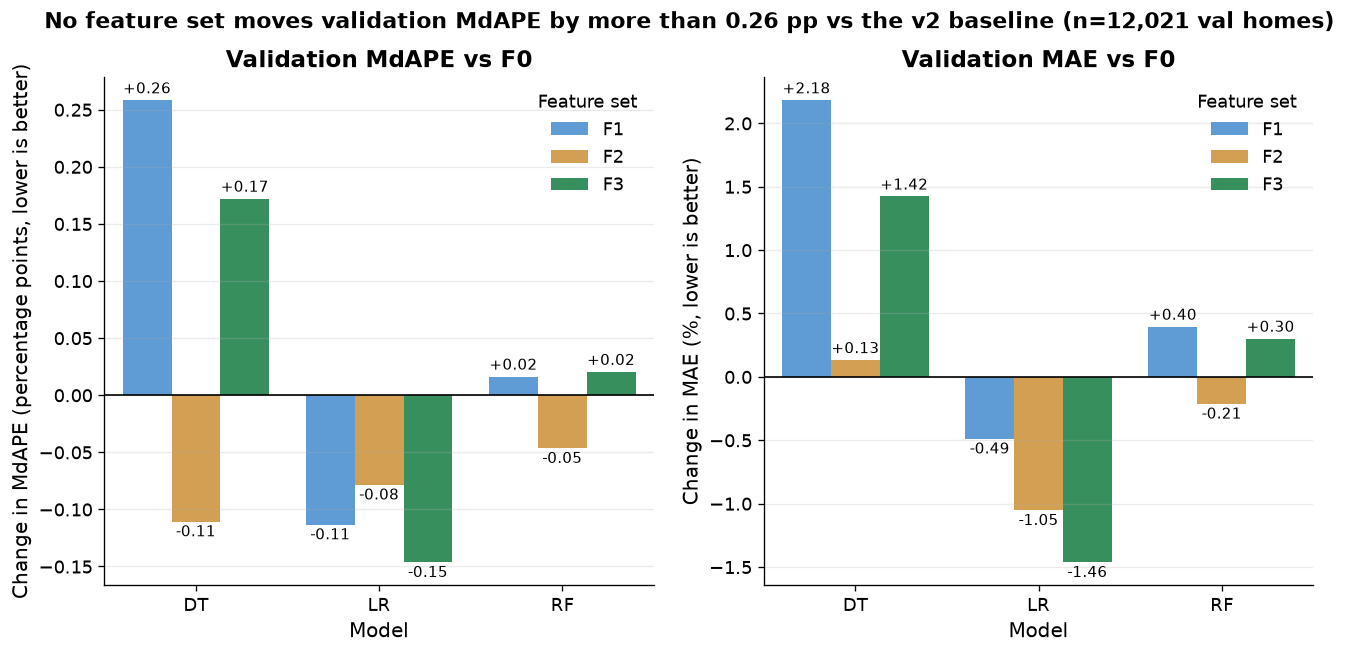

In [12]:
# Figure 1: change vs F0 on validation (all four feature sets)
dd = best.loc[~best['feature_set'].eq('F0')]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, col, title, label in [(axes[0], 'dMdAPE_pp', 'Validation MdAPE vs F0', 'Change in MdAPE (percentage points, lower is better)'),
                              (axes[1], 'dMAE_pct', 'Validation MAE vs F0', 'Change in MAE (%, lower is better)')]:
    sns.barplot(data=dd, x='model', y=col, hue='feature_set', hue_order=['F1', 'F2', 'F3'], ax=ax,
                palette=[ps.SET_COLORS[s] for s in ['F1', 'F2', 'F3']])
    for c in ax.containers:
        ax.bar_label(c, fmt='%+.2f', fontsize=9, padding=2)
    ax.axhline(0, color='k', lw=1)
    ax.set_title(title); ax.set_xlabel('Model'); ax.set_ylabel(label); ax.legend(title='Feature set', loc='best')
span = dd['dMdAPE_pp'].abs().max()
fig.suptitle(f'No feature set moves validation MdAPE by more than {span:.2f} pp vs the v2 baseline (n={len(val_rows):,} val homes)', fontweight='bold')
ps.save(fig, 'fig1_feature_set_comparison.png'); plt.show()

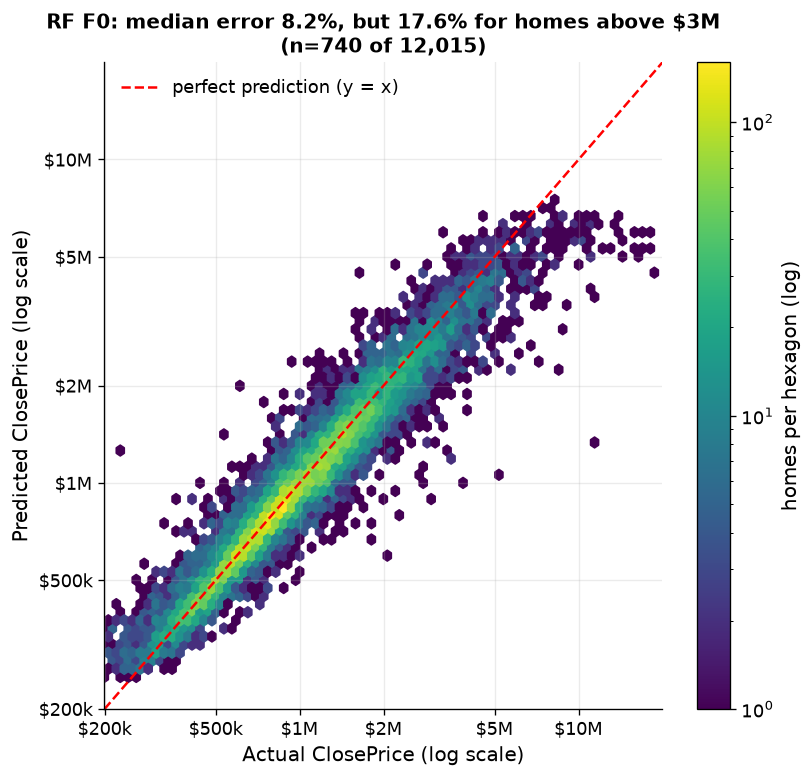

In [13]:
# Figure 2: actual vs predicted (log axes) for the final model with the lowest test MdAPE
best_key = min(preds, key=lambda k: np.median(np.abs(preds[k] - y_te) / y_te))
fig, ax = plt.subplots(figsize=(7.5, 7))
hb = ax.hexbin(np.log10(y_te), np.log10(preds[best_key]), gridsize=70, bins='log', mincnt=1, cmap='viridis',
               extent=(5.3, 7.3, 5.3, 7.3))
lim = np.array([5.3, 7.3]); ax.plot(lim, lim, 'r--', lw=1.5, label='perfect prediction (y = x)')
tick_vals = [2e5, 5e5, 1e6, 2e6, 5e6, 1e7]
for axis in (ax.xaxis, ax.yaxis):
    axis.set_ticks(np.log10(tick_vals)); axis.set_ticklabels(['$200k', '$500k', '$1M', '$2M', '$5M', '$10M'])
ax.set_xlim(5.3, 7.3); ax.set_ylim(5.3, 7.3)
ax.set_xlabel('Actual ClosePrice (log scale)'); ax.set_ylabel('Predicted ClosePrice (log scale)')
ape_b = np.abs(preds[best_key] - y_te) / y_te
mdape_b = np.median(ape_b)
hi_b = np.median(ape_b[y_te > 3e6])
ax.set_title(f'{best_key[0]} {best_key[1]}: median error {mdape_b:.1%}, but {hi_b:.1%} for homes above $3M\n(n={int((y_te > 3e6).sum()):,} of {len(y_te):,})', fontsize=12)
fig.colorbar(hb, label='homes per hexagon (log)'); ax.legend(loc='upper left')
ps.save(fig, 'fig2_actual_vs_predicted.png'); plt.show()

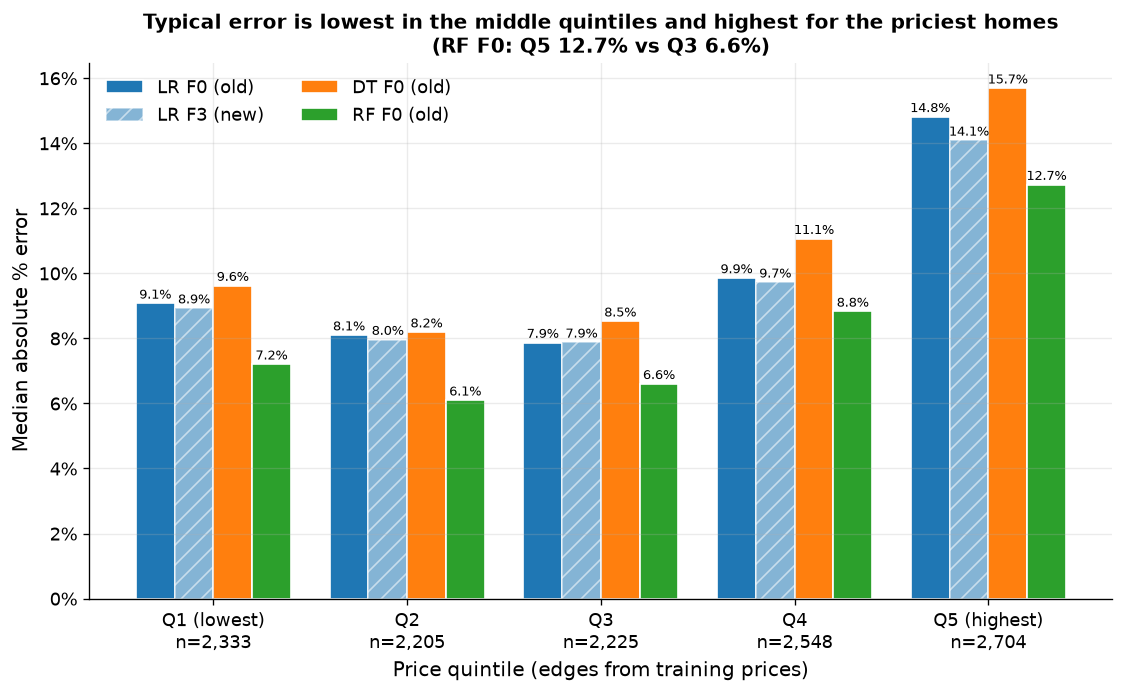

In [14]:
# Figure 3: MdAPE by price quintile, old vs chosen (hatched = new feature set)
fig, ax = plt.subplots(figsize=(11, 5.8))
keys = list(preds); w = 0.8 / len(keys)
for i, (m, fs) in enumerate(keys):
    vals = qtab[f'{m} {fs}'].to_numpy()
    bars = ax.bar(np.arange(5) + i * w - 0.4 + w / 2, vals, w, color=ps.MODEL_COLORS[m], alpha=1 if fs == 'F0' else 0.55,
                  hatch='' if fs == 'F0' else '//', edgecolor='white', label=f'{m} {fs}' + (' (old)' if fs == 'F0' else ' (new)'))
    ax.bar_label(bars, labels=[f'{v:.1%}' for v in vals], fontsize=7.5, padding=1)
ax.set_xticks(range(5)); ax.set_xticklabels([f'{l}\nn={n:,}' for l, n in zip(qlabel, qtab['n test homes'])])
ax.yaxis.set_major_formatter(ps.pct); ax.set_xlabel('Price quintile (edges from training prices)'); ax.set_ylabel('Median absolute % error')
rfq = qtab[f'{best_key[0]} {best_key[1]}']
ax.set_title(f'Typical error is lowest in the middle quintiles and highest for the priciest homes\n({best_key[0]} {best_key[1]}: Q5 {rfq.iloc[4]:.1%} vs Q3 {rfq.iloc[2]:.1%})', fontsize=12)
ax.legend(ncol=2, loc='upper left')
ps.save(fig, 'fig3_mdape_by_quintile.png'); plt.show()

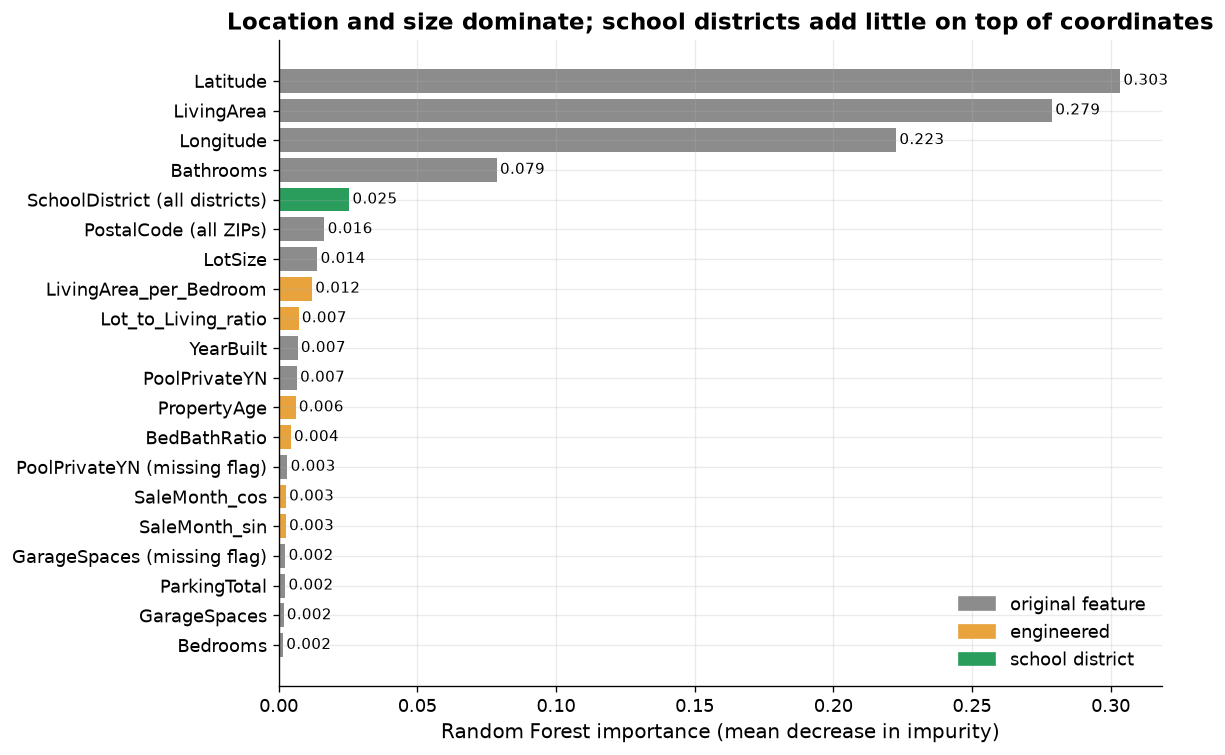

In [15]:
# Figure 4: top-20 RF importances on the FULL feature set (F3). Fit for interpretation only; never scored on test.
rf3 = build('RF', 'F3', 'onehot')
cols3 = ft.input_columns('F3', 'tree')
rf3.fit(train[cols3], train[mp.TARGET])
names = rf3.regressor_.named_steps['prep'].get_feature_names_out()
imp = pd.Series(rf3.regressor_.named_steps['model'].feature_importances_, index=names)
def group(n):
    if n.startswith('zip__'): return 'PostalCode (all ZIPs)'
    if n.startswith('district__'): return 'SchoolDistrict (all districts)'
    n = n.split('__', 1)[1]
    return n.replace('missingindicator_', '') + ' (missing flag)' if n.startswith('missingindicator_') else n
grouped = imp.groupby(imp.index.map(group)).sum().sort_values(ascending=False).head(20)[::-1]
color = ['#2a9d5c' if 'SchoolDistrict' in n else '#e8a33d' if n in ft.ENGINEERED else '#8c8c8c' for n in grouped.index]
fig, ax = plt.subplots(figsize=(9.5, 7))
bars = ax.barh(grouped.index, grouped.values, color=color); ax.bar_label(bars, fmt='%.3f', padding=2, fontsize=9)
ax.set_xlabel('Random Forest importance (mean decrease in impurity)')
ax.set_title('Location and size dominate; school districts add little on top of coordinates')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color='#8c8c8c', label='original feature'), Patch(color='#e8a33d', label='engineered'),
                   Patch(color='#2a9d5c', label='school district')], loc='lower right')
ps.save(fig, 'fig4_rf_importances.png'); plt.show()
imp_district = imp[imp.index.str.startswith('district__')].sum()   # total over ALL district columns

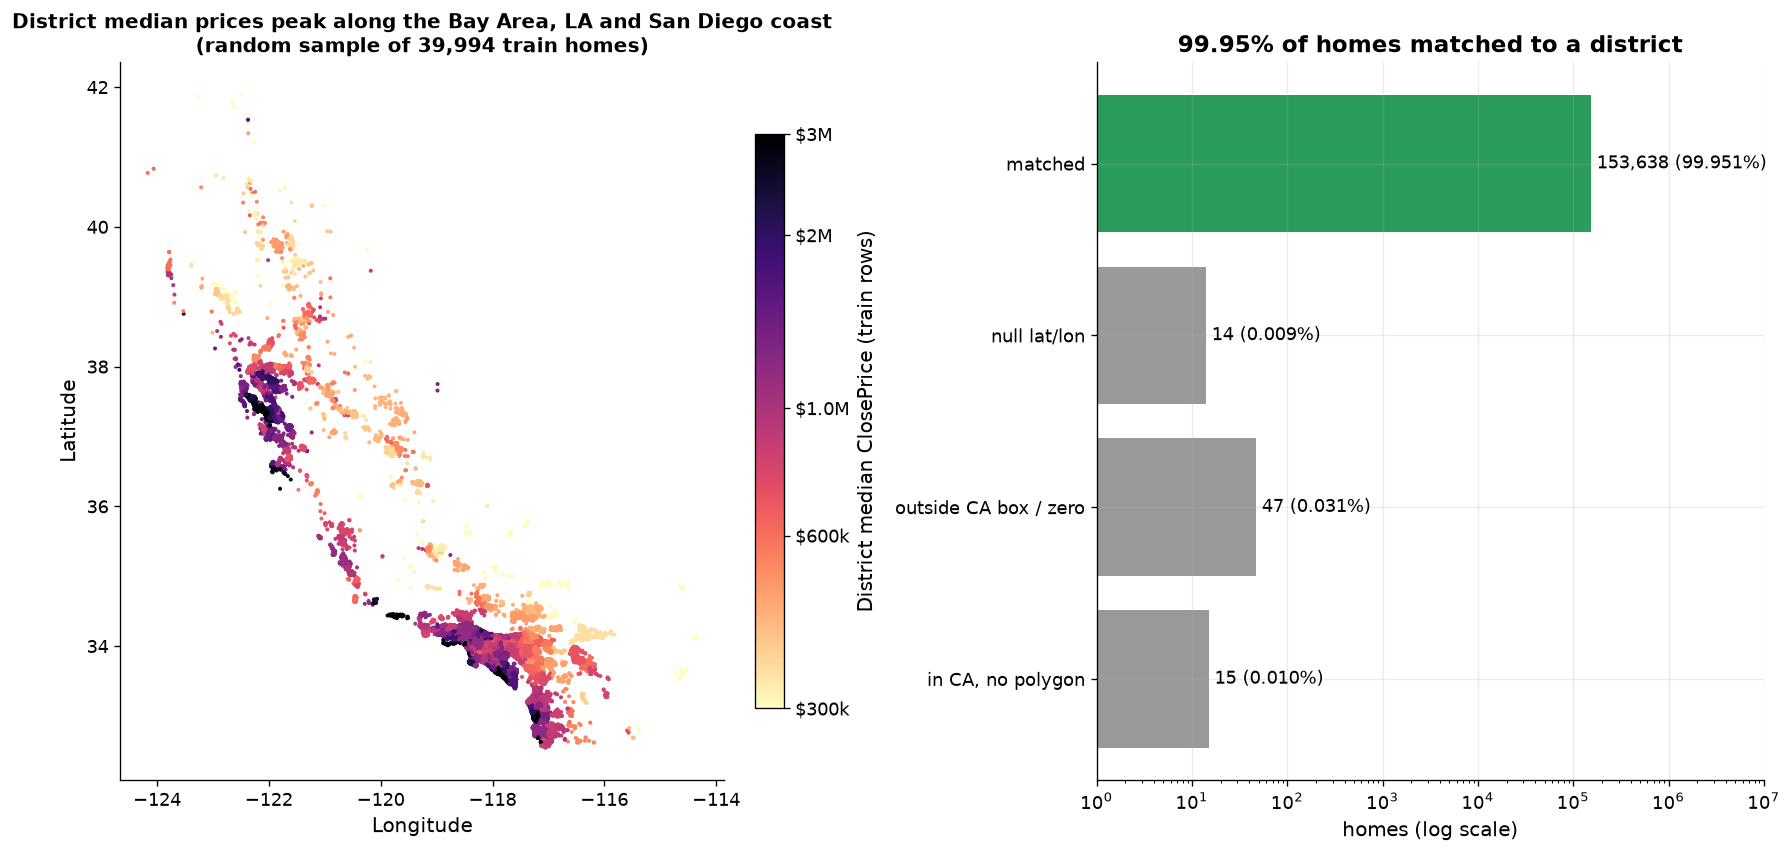

In [16]:
# Figure 5: map of homes by district median price (train rows, descriptive only) + match-rate breakdown
tr_j = joined.loc[joined['split'].eq('train') & joined['coord_valid']]
dist_med = tr_j.loc[tr_j['SchoolDistrict'].ne('Unknown')].groupby('SchoolDistrict')[mp.TARGET].median()
samp = tr_j.sample(40000, random_state=SEED)
samp = samp.assign(med=samp['SchoolDistrict'].map(dist_med)).dropna(subset=['med'])
fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={'width_ratios': [1.1, 1]}, constrained_layout=True)
sc = axes[0].scatter(samp['Longitude'], samp['Latitude'], c=samp['med'], s=2, cmap='magma_r',
                     norm=plt.matplotlib.colors.LogNorm(vmin=3e5, vmax=3e6), rasterized=True)
cb = fig.colorbar(sc, ax=axes[0], shrink=0.8, pad=0.02); cb.set_label('District median ClosePrice (train rows)')
cb.set_ticks([3e5, 6e5, 1e6, 2e6, 3e6]); cb.set_ticklabels(['$300k', '$600k', '$1.0M', '$2M', '$3M']); cb.ax.minorticks_off()
axes[0].set_xlabel('Longitude'); axes[0].set_ylabel('Latitude'); axes[0].set_aspect(1.25); axes[0].grid(False)
axes[0].set_title(f'District median prices peak along the Bay Area, LA and San Diego coast\n(random sample of {len(samp):,} train homes)', fontsize=12)
rp = report.iloc[[1, 3, 4, 5]].copy(); rp.index = ['matched', 'null lat/lon', 'outside CA box / zero', 'in CA, no polygon']
bars = axes[1].barh(rp.index[::-1], rp['rows'][::-1], color=['#999', '#999', '#999', '#2a9d5c'])
axes[1].set_xscale('log'); axes[1].set_xlabel('homes (log scale)')
for b, (n, p) in zip(bars, zip(rp['rows'][::-1], rp['pct'][::-1])):
    axes[1].text(n * 1.15, b.get_y() + b.get_height() / 2, f'{n:,.0f} ({p:.3f}%)', va='center')
axes[1].set_xlim(1, 1e7); axes[1].set_title(f'{report.loc["matched", "pct"]:.2f}% of homes matched to a district')
ps.save(fig, 'fig5_district_map_and_match_rate.png'); plt.show()

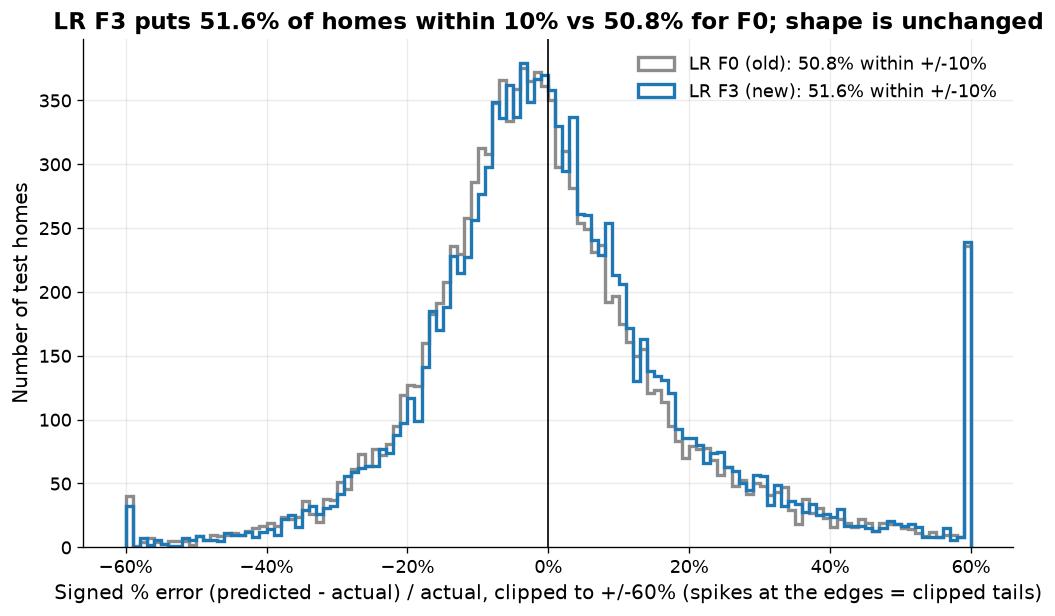

In [17]:
# Figure 6: signed % error distribution, old vs new (models whose feature set changed)
changed = [(m, fs) for (m, fs) in preds if fs != 'F0']
fig, ax = plt.subplots(figsize=(10, 5.5))
within_by = {}
for m, fs in changed:
    for key, col, lab in [((m, 'F0'), '#8c8c8c', f'{m} F0 (old)'), ((m, fs), ps.MODEL_COLORS[m], f'{m} {fs} (new)')]:
        err = np.clip((preds[key] - y_te) / y_te, -0.6, 0.6)
        within_by[key] = np.mean(np.abs((preds[key] - y_te) / y_te) <= 0.10)
        ax.hist(err, bins=120, range=(-0.6, 0.6), histtype='step', lw=2, color=col, label=f'{lab}: {within_by[key]:.1%} within +/-10%')
ax.axvline(0, color='k', lw=1); ax.xaxis.set_major_formatter(ps.pct)
ax.set_xlabel('Signed % error (predicted - actual) / actual, clipped to +/-60% (spikes at the edges = clipped tails)'); ax.set_ylabel('Number of test homes')
m0, fs0 = changed[0]
ax.set_title(f'{m0} {fs0} puts {within_by[(m0, fs0)]:.1%} of homes within 10% vs {within_by[(m0, "F0")]:.1%} for F0; shape is unchanged')
ax.legend()
ps.save(fig, 'fig6_error_distribution.png'); plt.show()

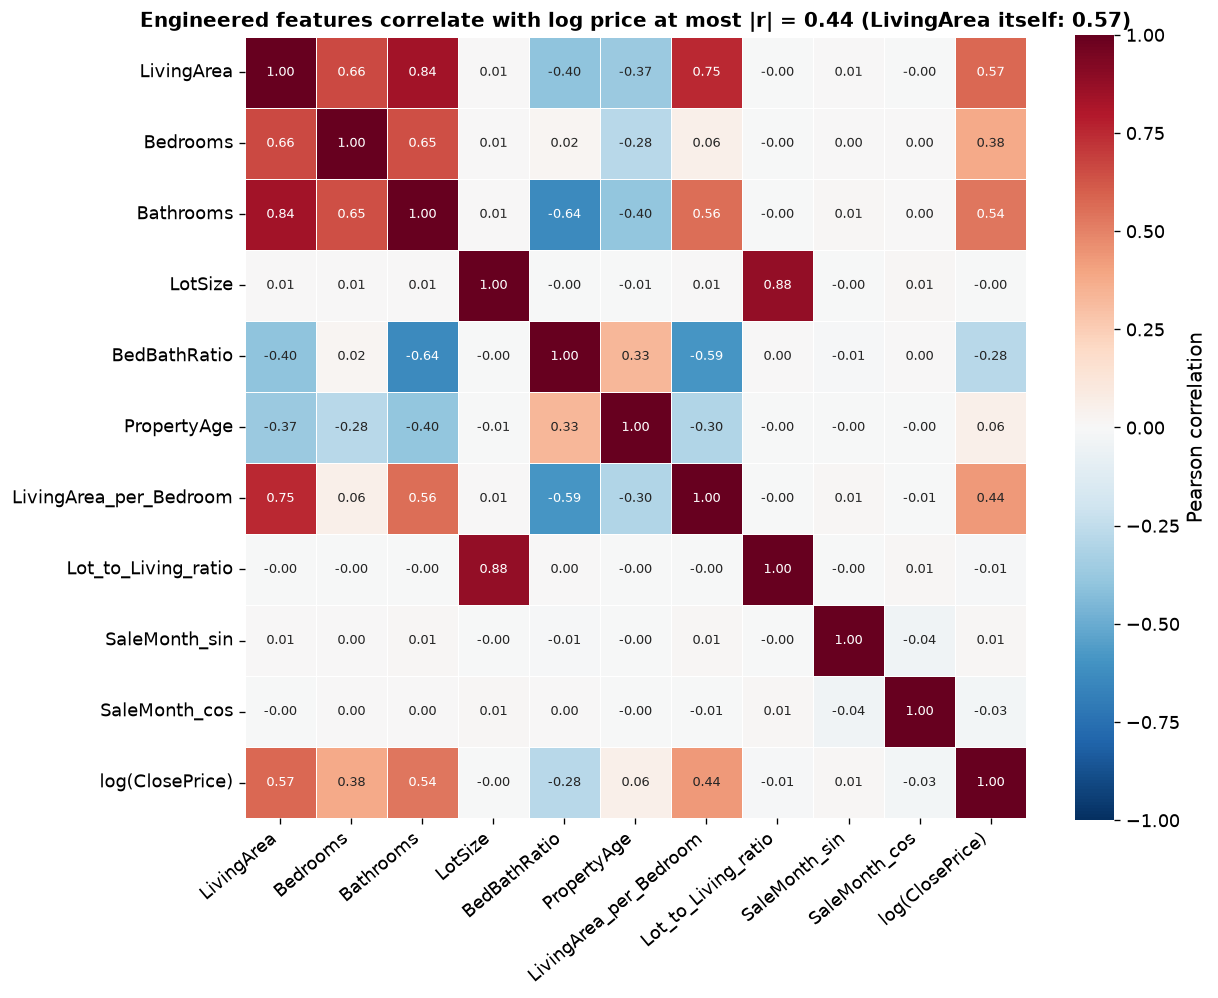

In [18]:
# Figure 7: correlation heatmap of numeric / engineered features (train rows)
hm_cols = ['LivingArea', 'Bedrooms', 'Bathrooms', 'LotSize'] + ft.ENGINEERED
hm = train[hm_cols].assign(**{'log(ClosePrice)': y_log}).corr()
fig, ax = plt.subplots(figsize=(10.5, 8.5))
sns.heatmap(hm, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, square=True, linewidths=.5, ax=ax,
            cbar_kws={'label': 'Pearson correlation'}, annot_kws={'size': 8})
eng_max = hm.loc[ft.ENGINEERED, 'log(ClosePrice)'].abs().max()
ax.grid(False); ax.set_title(f'Engineered features correlate with log price at most |r| = {eng_max:.2f} (LivingArea itself: {hm.loc["LivingArea", "log(ClosePrice)"]:.2f})', fontsize=12)
plt.setp(ax.get_xticklabels(), rotation=40, ha='right')
ps.save(fig, 'fig7_correlation_heatmap.png'); plt.show()

## 7. Conclusions (generated from the executed numbers above)

In [19]:
lines = []
for m in ['LR', 'DT', 'RF']:
    o = comp.loc[comp['model'].eq(m) & comp['feature_set'].eq('F0')].iloc[0]
    n = comp.loc[comp['model'].eq(m) & comp['feature_set'].eq(chosen[m][0])].iloc[0]
    v = best.loc[best['model'].eq(m)].set_index('feature_set')
    if chosen[m][0] == 'F0':
        lines.append(f'- **{m}: kept F0.** Best alternative on validation was {v.loc[v.index.difference(["F0"]), "MdAPE"].idxmin()} '
                     f'({v.loc[v.index.difference(["F0"]), "dMdAPE_pp"].min():+.2f} pp MdAPE) which did not clear the rule '
                     f'(>= {MIN_GAIN*100:.2f} pp and a lower MAE). Test result unchanged: MdAPE {o.test_MdAPE:.2%}, MAE ${o.test_MAE:,.0f}, R2 {o.test_R2:.4f}.')
    else:
        b = boot_df.loc[boot_df['model'].eq(m)].iloc[0]
        lines.append(f'- **{m}: chose {n.feature_set} ({n.description}).** Test MdAPE {o.test_MdAPE:.2%} -> {n.test_MdAPE:.2%} ({n.dMdAPE_pp:+.2f} pp, 95% CI {b["dMdAPE 95% CI (pp)"]}), '
                     f'MAE ${o.test_MAE:,.0f} -> ${n.test_MAE:,.0f} ({n.dMAE:+,.0f}, 95% CI {b["dMAE 95% CI"]}), R2 {o.test_R2:.4f} -> {n.test_R2:.4f}.')
display(Markdown('\n'.join(lines)))
display(Markdown(f"""
**Honest reading.**
- Best model on test is still **{best_key[0]} {best_key[1]}** (MdAPE {mdape_b:.2%}), the same model as Week 5; only LR changed, and it stays behind RF on MdAPE and MAE.
- Validation differences between feature sets are small and mixed in sign: MdAPE moves between {dd['dMdAPE_pp'].min():+.2f} and {dd['dMdAPE_pp'].max():+.2f} pp and MAE between {dd['dMAE_pct'].min():+.2f}% and {dd['dMAE_pct'].max():+.2f}% (DT gets worse with F1/F3). LR is the only model that improves consistently; its test gain is separated from zero by the bootstrap interval above, but it is modest, and F1 (engineered) and F2 (districts) each contribute part of it.
- Why so little: latitude/longitude and ZIP already carry most of the location signal, so districts add little for trees (RF importance of all district columns combined: {imp_district:.3f}); trees also cannot predict above the ~$8.9M training cap, which is where R2 is decided.
- R2 is dominated by the ~44 test sales above $10M, so MdAPE and MAE are the primary yardsticks.

**Limitations / next steps.** On validation, DT depth 24 ({f0_best:.2%} MdAPE) beat depth 18 ({f0_d18:.2%} MdAPE) on F0 and confirmed parity with tuned F2 target ({f2_best:.2%}, delta {dt_delta_pp:.3f} pp), while the final DT test fit still used depth 18 (listed as a limitation); LR F3 was essentially tied across district min_frequency thresholds ({lr_mf_min:.2%} to {lr_mf_max:.2%} MdAPE); district encodings tried were rare-grouped one-hot and 5-fold target encoding; no district-level aggregates (price per sqft) were built; no rolling-origin backtest yet (Week 8). 76 homes ({report.loc['unmatched', 'pct']:.3f}%) have no district. Week 7 will test gradient boosting, which typically uses categorical/geographic features better than a single tree.
"""))

- **LR: chose F3 (F1 + school district (full)).** Test MdAPE 9.80% -> 9.59% (-0.21 pp, 95% CI [-0.33, -0.08]), MAE $235,941 -> $228,644 (-7,297, 95% CI [-9,324, -5,443]), R2 0.4860 -> 0.5024.
- **DT: kept F0.** Best alternative on validation was F2 (-0.11 pp MdAPE) which did not clear the rule (>= 0.10 pp and a lower MAE). Test result unchanged: MdAPE 10.32%, MAE $256,543, R2 0.4303.
- **RF: kept F0.** Best alternative on validation was F2 (-0.05 pp MdAPE) which did not clear the rule (>= 0.10 pp and a lower MAE). Test result unchanged: MdAPE 8.19%, MAE $220,621, R2 0.4445.


**Honest reading.**
- Best model on test is still **RF F0** (MdAPE 8.19%), the same model as Week 5; only LR changed, and it stays behind RF on MdAPE and MAE.
- Validation differences between feature sets are small and mixed in sign: MdAPE moves between -0.15 and +0.26 pp and MAE between -1.46% and +2.18% (DT gets worse with F1/F3). LR is the only model that improves consistently; its test gain is separated from zero by the bootstrap interval above, but it is modest, and F1 (engineered) and F2 (districts) each contribute part of it.
- Why so little: latitude/longitude and ZIP already carry most of the location signal, so districts add little for trees (RF importance of all district columns combined: 0.025); trees also cannot predict above the ~$8.9M training cap, which is where R2 is decided.
- R2 is dominated by the ~44 test sales above $10M, so MdAPE and MAE are the primary yardsticks.

**Limitations / next steps.** On validation, DT depth 24 (10.27% MdAPE) beat depth 18 (10.39% MdAPE) on F0 and confirmed parity with tuned F2 target (10.24%, delta 0.035 pp), while the final DT test fit still used depth 18 (listed as a limitation); LR F3 was essentially tied across district min_frequency thresholds (9.58% to 9.62% MdAPE); district encodings tried were rare-grouped one-hot and 5-fold target encoding; no district-level aggregates (price per sqft) were built; no rolling-origin backtest yet (Week 8). 76 homes (0.049%) have no district. Week 7 will test gradient boosting, which typically uses categorical/geographic features better than a single tree.
